# Loan Default Prediction and Analysis 

## Introduction

The purpose of this project is to develop predictive models that estimate the likelihood of loan default based on borrower financial and credit characteristics. Specifically, this study examines whether borrower attributes such as income, loan amount, credit history, and employment status can accurately predict default risk. This research question reflects a common challenge faced by financial institutions when evaluating loan applications and managing credit portfolios. By applying predictive analytics techniques, this project aims to identify patterns in borrower data and assess the effectiveness of machine learning models in supporting credit risk assessment.

## Dataset Overview

The dataset used in this project is the Loan Default dataset obtained from Kaggle. <br>
The dataset contains borrower-level loan application information and is commonly used for predictive modeling and credit risk analysis. Each record in the dataset represents an individual loan applicant and includes several financial and demographic attributes.<br> 
Key variables in the dataset include applicant age, income, loan amount, credit history, employment status, and loan purpose. The target variable is the loan default status, a binary indicator of whether the borrower defaulted on the loan.

This dataset is well-suited for a predictive analytics course because it represents a real-world financial use case, includes structured tabular data, and supports multiple modeling approaches. 

### 2.1 Data Preparation

Load the dataset as a Pandas data frame

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Load the dataset file to Pandas DataFrame called 'loan'
loan = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/DSC680-T301-Applied-Data-Science/Dataset/Loan_default.csv')


In [3]:
# Preview the column names to verify structure
print(loan .columns)

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='object')


In [4]:
# Display the first 10 rows of the data set
print("\nThe first ten rows of data:")
print(loan.head(10))


The first ten rows of data:
       LoanID  Age  Income  LoanAmount  CreditScore  MonthsEmployed  \
0  I38PQUQS96   56   85994       50587          520              80   
1  HPSK72WA7R   69   50432      124440          458              15   
2  C1OZ6DPJ8Y   46   84208      129188          451              26   
3  V2KKSFM3UN   32   31713       44799          743               0   
4  EY08JDHTZP   60   20437        9139          633               8   
5  A9S62RQ7US   25   90298       90448          720              18   
6  H8GXPAOS71   38  111188      177025          429              80   
7  0HGZQKJ36W   56  126802      155511          531              67   
8  1R0N3LGNRJ   36   42053       92357          827              83   
9  CM9L1GTT2P   40  132784      228510          480             114   

   NumCreditLines  InterestRate  LoanTerm  DTIRatio    Education  \
0               4         15.23        36      0.44   Bachelor's   
1               1          4.81        60      0.68  

In [5]:
# Preview the column names and counts and data types
print(loan.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

#### 2.1(a) Check for missing values

In [6]:
# Using .isnull() to find missing values
loan.isnull().sum()


LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

Dataset without any missing values. 

#### 2.1(b) Check for duplicates

In [7]:
# Using duplicated() to check the total number of duplicate rows in the dataset
duplicate_count = loan.duplicated().sum()

# Display duplicate count if any 
print(f"Number of duplicate rows: {duplicate_count}")


Number of duplicate rows: 0


Dataset without any duplicate rows.

#### 2.1(c) Normalize and Validate Variable Name

In [8]:
# Copy the data frame without modifying the original
loan_new = loan.copy()

In [9]:
# Normalize column names
loan_new.columns = (
    loan_new.columns
        .str.lower()          # Using lower() to convert to lowercase
        .str.strip(' ')                       # Using strip() to remove leading/trailing spaces
)

# Display all variable names in the new dataset
print(loan_new.columns.tolist())



['loanid', 'age', 'income', 'loanamount', 'creditscore', 'monthsemployed', 'numcreditlines', 'interestrate', 'loanterm', 'dtiratio', 'education', 'employmenttype', 'maritalstatus', 'hasmortgage', 'hasdependents', 'loanpurpose', 'hascosigner', 'default']


#### 2.1(d) Validate and Clean Categorical Variables

In [10]:
# Convert YES/NO columns to binary indicators
binary_cols = ['hasmortgage', 'hasdependents', 'hascosigner']

loan_new[binary_cols] = loan_new[binary_cols].replace({'Yes': 1, 'No': 0})


Transforms categorical promotion variables into a numeric format suitable for modeling and analysis.

In [11]:
# Preview the column names and counts and data types
print(loan_new.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   loanid          255347 non-null  object 
 1   age             255347 non-null  int64  
 2   income          255347 non-null  int64  
 3   loanamount      255347 non-null  int64  
 4   creditscore     255347 non-null  int64  
 5   monthsemployed  255347 non-null  int64  
 6   numcreditlines  255347 non-null  int64  
 7   interestrate    255347 non-null  float64
 8   loanterm        255347 non-null  int64  
 9   dtiratio        255347 non-null  float64
 10  education       255347 non-null  object 
 11  employmenttype  255347 non-null  object 
 12  maritalstatus   255347 non-null  object 
 13  hasmortgage     255347 non-null  int64  
 14  hasdependents   255347 non-null  int64  
 15  loanpurpose     255347 non-null  object 
 16  hascosigner     255347 non-null  int64  
 17  default   

In [12]:
# Display the first 10 rows of the data set
print("\nThe first ten rows of data:")
print(loan_new.head(10))


The first ten rows of data:
       loanid  age  income  loanamount  creditscore  monthsemployed  \
0  I38PQUQS96   56   85994       50587          520              80   
1  HPSK72WA7R   69   50432      124440          458              15   
2  C1OZ6DPJ8Y   46   84208      129188          451              26   
3  V2KKSFM3UN   32   31713       44799          743               0   
4  EY08JDHTZP   60   20437        9139          633               8   
5  A9S62RQ7US   25   90298       90448          720              18   
6  H8GXPAOS71   38  111188      177025          429              80   
7  0HGZQKJ36W   56  126802      155511          531              67   
8  1R0N3LGNRJ   36   42053       92357          827              83   
9  CM9L1GTT2P   40  132784      228510          480             114   

   numcreditlines  interestrate  loanterm  dtiratio    education  \
0               4         15.23        36      0.44   Bachelor's   
1               1          4.81        60      0.68  

In [13]:
# Inspect unique values for categorical columns
cat_cols = ['education', 'employmenttype', 'maritalstatus', 'loanpurpose']

for col in cat_cols:
    print(f"{col}: {loan_new[col].unique()}")


education: ["Bachelor's" "Master's" 'High School' 'PhD']
employmenttype: ['Full-time' 'Unemployed' 'Self-employed' 'Part-time']
maritalstatus: ['Divorced' 'Married' 'Single']
loanpurpose: ['Other' 'Auto' 'Business' 'Home' 'Education']


All categories are spelled consistently and contain no unexpected values.

#### 2.1(e) Validate Numerical Variables

In [14]:
# Preview the column names and counts and data types
print(loan_new.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   loanid          255347 non-null  object 
 1   age             255347 non-null  int64  
 2   income          255347 non-null  int64  
 3   loanamount      255347 non-null  int64  
 4   creditscore     255347 non-null  int64  
 5   monthsemployed  255347 non-null  int64  
 6   numcreditlines  255347 non-null  int64  
 7   interestrate    255347 non-null  float64
 8   loanterm        255347 non-null  int64  
 9   dtiratio        255347 non-null  float64
 10  education       255347 non-null  object 
 11  employmenttype  255347 non-null  object 
 12  maritalstatus   255347 non-null  object 
 13  hasmortgage     255347 non-null  int64  
 14  hasdependents   255347 non-null  int64  
 15  loanpurpose     255347 non-null  object 
 16  hascosigner     255347 non-null  int64  
 17  default   

In [15]:
# Check for invalid or extreme values
loan_new[['age', 'income', 'loanamount','creditscore', 'monthsemployed', 'numcreditlines', 'interestrate', 'loanterm', 'dtiratio']].describe()


,age,income,loanamount,creditscore,monthsemployed,numcreditlines,interestrate,loanterm,dtiratio
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000


In [16]:
# Display the first 10 rows of the data set
print("\nThe first ten rows of data:")
print(loan_new.head(10))


The first ten rows of data:
       loanid  age  income  loanamount  creditscore  monthsemployed  \
0  I38PQUQS96   56   85994       50587          520              80   
1  HPSK72WA7R   69   50432      124440          458              15   
2  C1OZ6DPJ8Y   46   84208      129188          451              26   
3  V2KKSFM3UN   32   31713       44799          743               0   
4  EY08JDHTZP   60   20437        9139          633               8   
5  A9S62RQ7US   25   90298       90448          720              18   
6  H8GXPAOS71   38  111188      177025          429              80   
7  0HGZQKJ36W   56  126802      155511          531              67   
8  1R0N3LGNRJ   36   42053       92357          827              83   
9  CM9L1GTT2P   40  132784      228510          480             114   

   numcreditlines  interestrate  loanterm  dtiratio    education  \
0               4         15.23        36      0.44   Bachelor's   
1               1          4.81        60      0.68  

### 2.2 Exploratory Data Analysis

Exploratory data analysis revealed several patterns in the dataset. Several visualizations provide clear and complementary insights into the loan default dataset. For example, borrowers with lower credit scores and lower incomes had higher default rates. Employment stability also appeared to influence default behavior, with unemployed or part-time workers demonstrating higher default rates than full-time employees. Additionally, certain loan types, such as business or auto loans, had slightly higher default rates than home loans.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve

#### 2.2(a) Create Histograms of Credit Score and Income Distribution

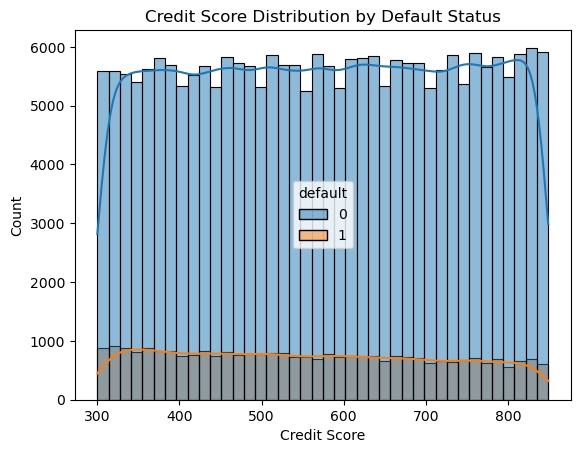

In [18]:
# Using histplot() to plot a histogram of Credit Score Distribution
plt.figure()
sns.histplot(data=loan_new, x="creditscore", hue="default", bins=40, kde=True)
plt.title("Credit Score Distribution by Default Status")
plt.xlabel("Credit Score")
plt.ylabel("Count")
plt.show()


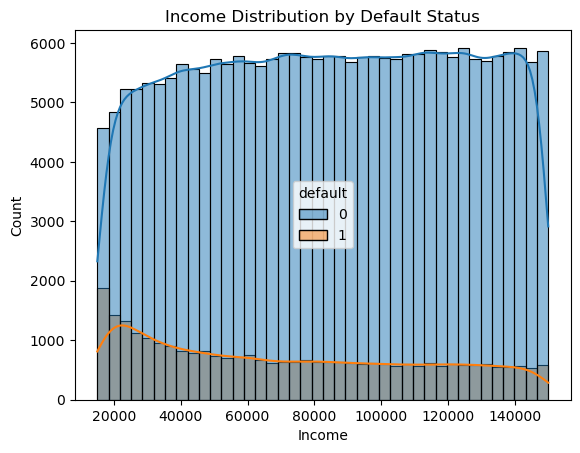

In [19]:
# Using histplot() to plot a histogram of Income Distribution
plt.figure()
sns.histplot(data=loan_new, x="income", hue="default", bins=40, kde=True)
plt.title("Income Distribution by Default Status")
plt.xlabel("Income")
plt.ylabel("Count")
plt.show()


The distribution plots for credit score and income show noticeable differences between defaulters and non-defaulters, with defaults occurring more frequently among borrowers with lower credit scores and lower incomes.
While the distributions still overlap, these patterns suggest that credit score and income remain meaningful but not sufficient predictors on their own.

#### 2.2(b) Create Boxplots of Loan Amount and Debt-to-Income Ratio (DTI) by Default Status

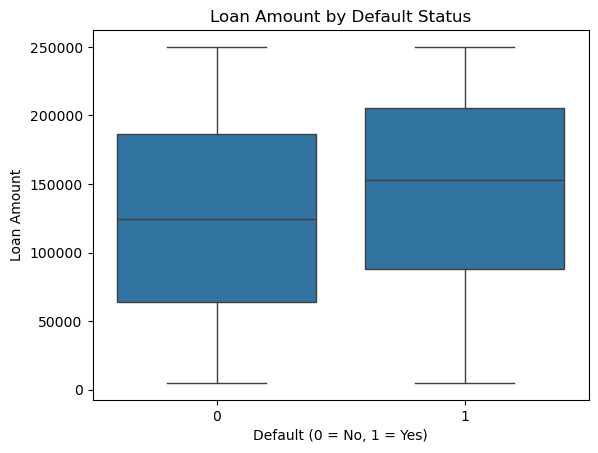

In [20]:
# Using boxplot() to plot a boxplot of Loan Amount
plt.figure()
sns.boxplot(data=loan_new, x="default", y="loanamount")
plt.title("Loan Amount by Default Status")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Loan Amount")
plt.show()


Borrowers who defaulted tend to have slightly higher average loan amounts than those who did not. The median loan amount for defaulted loans appears higher than that for non-defaulted loans.

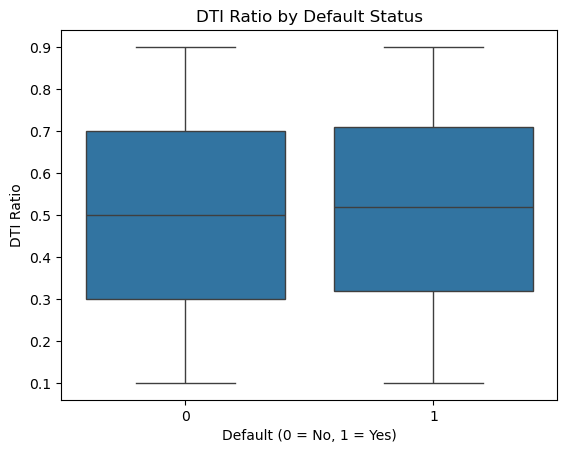

In [21]:
# Using boxplot() to plot a boxplot of Debt-to-Income Ratio (DTI)
plt.figure()
sns.boxplot(data=loan_new, x="default", y="dtiratio")
plt.title("DTI Ratio by Default Status")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("DTI Ratio")
plt.show()


The median DTI ratio for borrowers who defaulted is slightly higher than for those who did not default.<br>

Both boxplots suggest that borrowers who default tend to have slightly higher loan amounts and slightly higher debt-to-income ratios. However, the large overlap between the two groups indicates that these variables alone cannot fully explain loan default behavior.

#### 2.2(c) Create Bar charts of the Default Rate by Employment Type and Loan Purpose

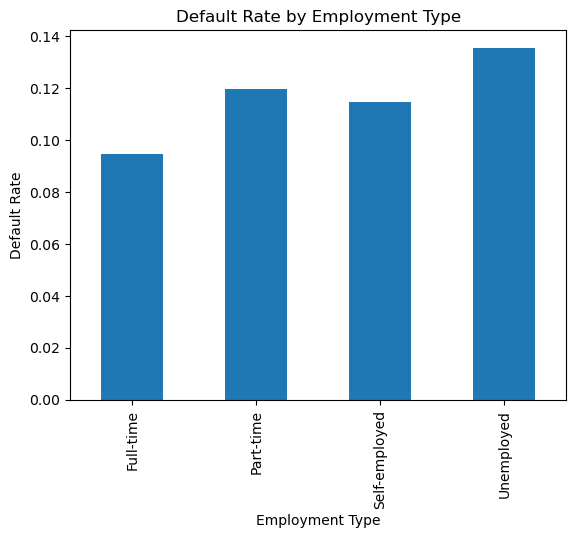

In [22]:
# Create a bar chart of Default Rate by Employment Type
employment_default_rate = loan_new.groupby("employmenttype")["default"].mean()

employment_default_rate.plot(kind="bar")
plt.title("Default Rate by Employment Type")
plt.ylabel("Default Rate")
plt.xlabel("Employment Type")
plt.show()


Bar charts of default rates across categorical variables further highlight structural differences in risk. Unemployed and part-time borrowers exhibit higher default rates than full-time employees, indicating that employment stability is an important risk factor.

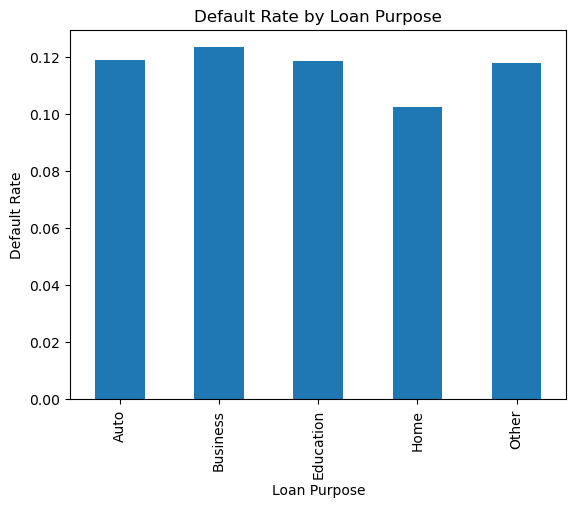

In [23]:
# Create a bar chart of Default Rate by Loan Purpose
loanpurpose_default_rate = loan_new.groupby("loanpurpose")["default"].mean()

loanpurpose_default_rate.plot(kind="bar")
plt.title("Default Rate by Loan Purpose")
plt.ylabel("Default Rate")
plt.xlabel("Loan Purpose")
plt.show()


Similarly, business and auto loans show slightly higher default rates than home loans, which appear to be relatively lower risk.

#### 2.2(d) Create a Correlation Heatmap of Numeric Variables

__correlation analysis__<br>
A correlation analysis of the numeric variables showed relatively low multicollinearity, suggesting that multiple predictors could be included in predictive models without causing significant redundancy. However, the dataset also showed a notable class imbalance, where non-default cases greatly outnumbered default cases. This imbalance required careful consideration during model evaluation.


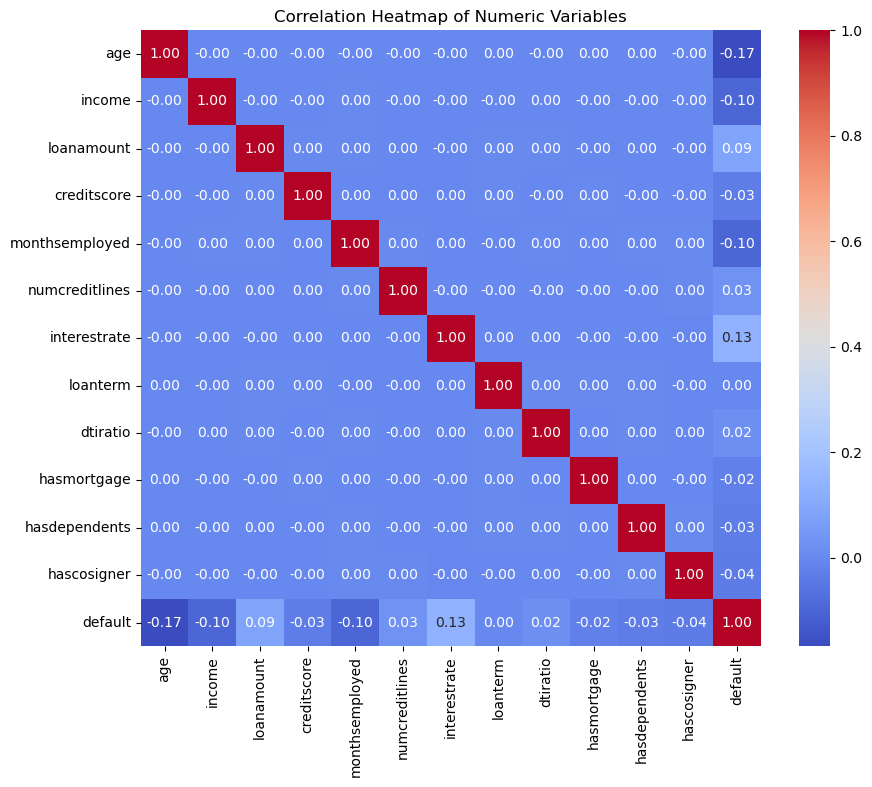

In [24]:
# Using heatmap() to create a Correlation Heatmap 
numeric_cols = loan_new.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(10, 8))
sns.heatmap(numeric_cols.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()


Interest rate and age show stronger relationships than other features, reinforcing the need for multivariate modeling rather than single-variable rules.

#### 2.2(e) Create a ROC Curve and Precision–Recall Curve

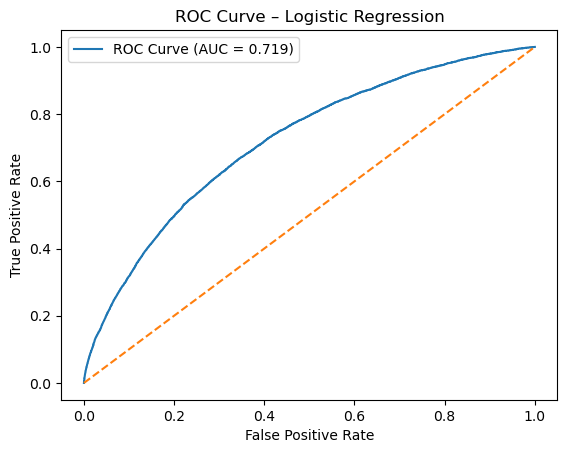

In [25]:
# Create a ROC Curve
X = loan_new[numeric_cols.columns.drop("default")]
y = loan_new["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_probs)
auc_score = roc_auc_score(y_test, y_probs)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Logistic Regression")
plt.legend()
plt.show()


The ROC curve (AUC ≈ 0.72) indicates that the logistic regression model has reasonable discriminatory power and moderate predictive ability.

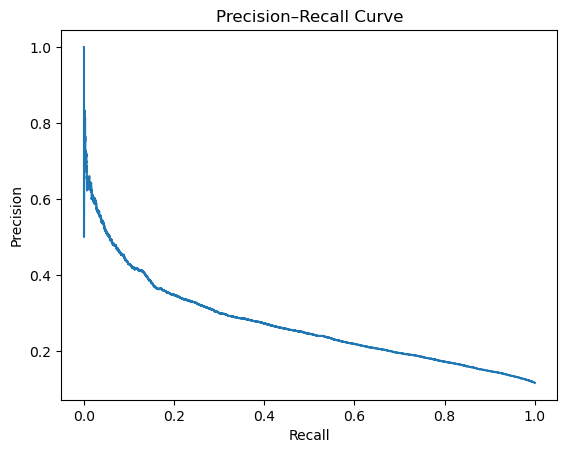

In [26]:
# Create a Precision–Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_probs)

plt.figure()
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.show()


Precision is high when recall is very low, as recall increases (the model tries to capture more defaulters), precision drops significantly. The curve shows that the model struggles to maintain both high precision and high recall simultaneously.
The precision–recall curve highlights the trade-off between capturing defaulters and maintaining precision in an imbalanced dataset.

## Methods of Analysis

This project approaches loan default prediction as a supervised binary classification problem. Two machine learning models were developed and evaluated: Logistic Regression and Random Forest.

Logistic Regression was used as the baseline model because it is widely used in credit risk modeling for its interpretability and strong statistical foundation. Financial institutions often prefer interpretable models because they allow decision-makers to understand how individual variables influence predictions.

Random Forest was selected as a second model because it can capture nonlinear relationships and interactions among variables. As an ensemble learning method, Random Forest combines multiple decision trees to improve predictive performance and reduce overfitting.

### 3.1. Data preparation

Before building the models, several data preparation steps were performed. 

In [27]:
# Preview the column names and counts and data types
print(loan_new.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   loanid          255347 non-null  object 
 1   age             255347 non-null  int64  
 2   income          255347 non-null  int64  
 3   loanamount      255347 non-null  int64  
 4   creditscore     255347 non-null  int64  
 5   monthsemployed  255347 non-null  int64  
 6   numcreditlines  255347 non-null  int64  
 7   interestrate    255347 non-null  float64
 8   loanterm        255347 non-null  int64  
 9   dtiratio        255347 non-null  float64
 10  education       255347 non-null  object 
 11  employmenttype  255347 non-null  object 
 12  maritalstatus   255347 non-null  object 
 13  hasmortgage     255347 non-null  int64  
 14  hasdependents   255347 non-null  int64  
 15  loanpurpose     255347 non-null  object 
 16  hascosigner     255347 non-null  int64  
 17  default   

#### 3.1(a) Remove Irrelevant Identifiers

First, irrelevant identifiers such as loan ID were removed from the dataset. The target variable was separated from the predictor variables. 

In [28]:
# Drop ID Column
loan_clean = loan_new.drop(columns=['loanid'])

# Separate Features & Target
x = loan_clean.drop('default', axis=1)
y = loan_clean['default']


#### 3.1(b) One-Hot Encode Categorical Variables

Categorical variables were converted to numerical values using one-hot encoding to ensure compatibility with machine learning algorithms. <br>
Categorical columns: education, employmenttype, maritalstatus, loanpurpose

In [29]:
# Using get_dummies to encode categorical variables
x = pd.get_dummies(x, drop_first=True)


In [30]:
# Preview the first 5 rows of dataset x
print(x.head())

   age  income  loanamount  creditscore  monthsemployed  numcreditlines  \
0   56   85994       50587          520              80               4   
1   69   50432      124440          458              15               1   
2   46   84208      129188          451              26               3   
3   32   31713       44799          743               0               3   
4   60   20437        9139          633               8               4   

   interestrate  loanterm  dtiratio  hasmortgage  ...  education_PhD  \
0         15.23        36      0.44            1  ...          False   
1          4.81        60      0.68            0  ...          False   
2         21.17        24      0.31            1  ...          False   
3          7.07        24      0.23            0  ...          False   
4          6.51        48      0.73            0  ...          False   

   employmenttype_Part-time  employmenttype_Self-employed  \
0                     False                         Fal

#### 3.1(c) Train-Test Dateset Split

The dataset was then split into training and testing sets using stratified sampling to preserve the class distribution.

In [31]:
# Import library
from sklearn.model_selection import train_test_split


In [32]:
# Split the data into 80% as the training dataset and 20% as the test dataset.
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)


### 3.2 Build Predictive Models

Two classification models were developed: Logistic Regression as a baseline model and Random Forest as a more advanced ensemble method. 

#### 3.2(a) Build A Logistic Regression Model

Logistic Regression was selected as the initial baseline model because it is highly interpretable, which is important in financial applications, performs well for binary classification problems such as default prediction, provides probability estimates for risk assessment, and serves as a reliable benchmark for comparison with more complex machine learning models.

In [33]:
# Import libraries
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

In [34]:
# Using sklearn to build a logistic Regression model
model = LogisticRegression(max_iter=1000)

# Using training data set to fit the model
model.fit(x_train, y_train)


LogisticRegression(max_iter=1000)

#### 3.2(b) Build A Random Forest Model

Random Forest was chosen for its ability to capture nonlinear relationships and feature interactions. This effectively captures nonlinear relationships, automatically detects interactions between variables, and reduces overfitting through its ensemble bagging approach.

In [35]:
# Import libraries
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.model_selection import train_test_split

In [36]:
# Build a Random Forest model
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'   # helps with class imbalance
)

# Using training data set to fit the model
rf.fit(x_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

### 3.3 Predictive Models Evaluation

Because the dataset contained class imbalance, additional evaluation metrics were used beyond overall accuracy. The models were evaluated using precision, recall, F1-score, and the area under the receiver operating characteristic curve (ROC-AUC). A confusion matrix was also analyzed to examine false positives and false negatives, which have important implications in financial decision-making.

#### 3.3.1 Logistic Regression Model Evaluation

#### 3.3.1(a) Accuracy

In [37]:
# Using predict() to predict test data
y_pred_lr = model.predict(x_test)

# Using accuracy_score() to get the model accuracy
accuracy_score(y_test, y_pred_lr)


0.8840415116506756

Due to the imbalanced dataset, accuracy alone is NOT enough for default prediction.

#### 3.3.1(b) Confusion Matrix

In [38]:
# Using confusion_matrix() to calculate the Confusion Matrix
confusion_matrix(y_test, y_pred_lr)


array([[45091,    48],
       [ 5874,    57]], dtype=int64)

__Observation of Confusion Matrix__<br>

* 45,091 non-default loans were correctly classified (True Negatives)
* 48 non-default loans were incorrectly classified as default (False Positives)
* 5,874 default loans were incorrectly classified as non-default (False Negatives)
* Only 57 default loans were correctly classified (True Positives)

#### 3.3.1(c) Precision, Recall, F1

In [39]:
# Display the classification report
print(classification_report(y_test, y_pred_lr))


              precision    recall  f1-score   support

           0       0.88      1.00      0.94     45139
           1       0.54      0.01      0.02      5931

    accuracy                           0.88     51070
   macro avg       0.71      0.50      0.48     51070
weighted avg       0.85      0.88      0.83     51070



__Observation of the Classification Report__<br>

* For non-default (Class 0): Precision = 0.88, Recall = 1.00, F1-score = 0.94. This means the model is highly effective at identifying borrowers who will not default.
* For default (Class 1): Precision = 0.54, Recall = 0.01, F1-score = 0.02. The extremely low recall (1%) means the model fails to identify most borrowers who actually default. 

#### 3.3.1(d) ROC-AUC

In [40]:
# Calculate the ROC-AUC score
y_prob_lr = model.predict_proba(x_test)[:,1]
roc_auc_score(y_test, y_prob_lr)


0.7303920762801326

The ROC-AUC score of 0.73 indicates that the model has a moderate ability to distinguish between default and non-default borrowers.

Logistic Regression model Interpretion:

* The Logistic Regression model achieved an overall accuracy of 0.88 (88%), which indicates that the model correctly classified 88% of all loan cases. However, accuracy alone can be misleading in this case because non-default cases significantly outnumber default cases.
* The confusion matrix shows that the model performs very well at identifying non-default borrowers. However, the 5,874 false negatives show the model struggles significantly to detect actual default cases.
* The model has an extremely low recall, indicating it fails to identify most borrowers who actually default. This is a critical limitation because detecting default risk is the primary objective.
* This ROC-AUC score suggests that while the model has some predictive capability, it is not effectively capturing default risk at the current classification threshold.

A Logistic Regression model was first implemented as a baseline classifier. Although the Logistic Regression model shows high overall accuracy and reasonable ROC-AUC performance, it performs poorly in identifying default cases due to severe class imbalance. The very low recall for default borrowers indicates that most high-risk loans are being misclassified as low risk. This makes the model unreliable for practical default prediction without further improvements.

#### 3.3.2 Random Forest Model Evaluation

#### 3.3.2(a) Predictions with Default Cutoff

In [41]:
# Predictions of Random Forest uses 0.5 as the default cutoff
y_pred_rf = rf.predict(x_test)
y_prob_rf = rf.predict_proba(x_test)[:, 1]

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred_rf)
f1 = f1_score(y_test, y_pred_rf)
roc_auc = roc_auc_score(y_test, y_prob_rf)

print("\nRandom Forest model key metrics:")
print("\nAccuracy:", accuracy)
print("\nF1 Score:", f1)
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nROC-AUC:", roc_auc)


Random Forest model key metrics:

Accuracy: 0.8848834932445663

F1 Score: 0.027460711331679072

Classification Report:
               precision    recall  f1-score   support

           0       0.89      1.00      0.94     45139
           1       0.73      0.01      0.03      5931

    accuracy                           0.88     51070
   macro avg       0.81      0.51      0.48     51070
weighted avg       0.87      0.88      0.83     51070


ROC-AUC: 0.7466589338690792


Random Forest Model with Default Cutoff Interpretation:<br>
* The Random Forest model achieved an overall accuracy of 0.88, which indicates that the model correctly classified 88% of all loan cases. However, accuracy can be misleading because the data is imbalanced (many non-defaulters, few defaulters).
* The F1 Score = 0.03 for default, which is extremely poor; it indicates that the model struggled to identify borrowers who defaulted correctly, and it failed to detect a large proportion of actual defaulters.
* The model has an extremely low recall of 0.01 for the default, which indicates it fails to identify most borrowers who actually default. The model identifies only 1% of actual defaulters.
* This ROC-AUC score of 0.746 suggests that the model has a moderate ability to separate defaulters from non-defaulters. However, it is not effectively capturing default risk at the current classification threshold.

#### 3.3.2(b) Predictions with Threshold Tuning

In [42]:
# Decision Threshold Tuning (Random Forest)
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Evaluate multiple decision thresholds to balance default recall against false positives
thresholds = [0.50, 0.30, 0.25, 0.20]
results = []

for thresh in thresholds:
    # Apply custom probability threshold instead of default 0.50
    y_pred_thresh = (y_prob_rf >= thresh).astype(int)
    
    # Extract confusion matrix counts
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thresh).ravel()
    
    results.append({
        "Threshold": thresh,
        "Precision (Default)": round(precision_score(y_test, y_pred_thresh), 3),
        "Recall (Default)": round(recall_score(y_test, y_pred_thresh), 3),
        "F1-Score (Default)": round(f1_score(y_test, y_pred_thresh), 3),
        "True Positives (Caught)": tp,
        "False Positives (Denied Good)": fp
    })

# Display comparison table
threshold_df = pd.DataFrame(results)
print("Random Forest Threshold Tuning Comparison:")
print(threshold_df.to_string(index=False))

Random Forest Threshold Tuning Comparison:
 Threshold  Precision (Default)  Recall (Default)  F1-Score (Default)  True Positives (Caught)  False Positives (Denied Good)
      0.50                0.734             0.015               0.030                       91                             33
      0.30                0.438             0.165               0.240                      980                           1260
      0.25                0.376             0.265               0.311                     1569                           2604
      0.20                0.320             0.405               0.358                     2401                           5100


Random Forest Model Threshold Tuning Interpretation:<br>

Lowering the probability cutoff shifts the classification boundary to capture significantly more high-risk borrowers while demonstrating a clear trade-off between default detection and false rejections.<br>
* Threshold = 0.30: Recall increases more than tenfold from 0.015 to 0.165 (catching 980 defaults), while precision adjusts to 0.438 and false positives rise modestly to 1,260.<br>
* Threshold = 0.25 (Recommended Operating Cutoff): Recall climbs to 0.265 (catching 1,569 defaults—over 17 times more than the baseline), lifting the F1-score from 0.030 to 0.311. Precision remains practical at 0.376 (nearly 4 in 10 flagged applicants are true defaulters), while false positives are held to 2,604 out of 45,139 creditworthy applicants (roughly 5.8%).<br>
* Threshold = 0.20: Recall reaches 0.405 (catching 2,401 defaults) with the highest F1-score (0.358), but false positives nearly double from 2,604 to 5,100, turning away over 11% of qualified borrowers.<br>

## Results & Findings Explained

Both Logistic Regression and Random Forest models were developed to predict loan default risk, and their performance was evaluated using accuracy, F1 score, and ROC-AUC. Logistic Regression achieved an accuracy of 0.88 and a ROC-AUC of 0.73. In contrast, the Random Forest model achieved slightly higher accuracy (0.885) and a higher ROC-AUC (0.747).

The results indicate that both models correctly classify most non-default borrowers. Random Forest slightly outperformed Logistic Regression in discrimination, achieving a higher ROC-AUC score. This suggests that Random Forest is better at distinguishing between borrowers who will default and those who will not, likely because it can capture complex nonlinear relationships and interactions among variables that Logistic Regression cannot.

However, at the default 0.50 cutoff, both models struggled to catch actual default cases due to severe class imbalance in the dataset. Logistic Regression produced a recall of 0.01 and an F1 score of 0.02 for the default class, while Random Forest showed only a slight improvement with a recall of 0.015 (catching just 91 of 5,931 defaults) and an F1 score of 0.03. Although Random Forest achieved higher precision (0.734) when flagging defaults, its near-99 % miss rate of high-risk borrowers made the default threshold unsuitable for practical credit risk management.

To address this limitation, post-processing threshold tuning was applied to the Random Forest-predicted probabilities across multiple cutoffs (0.50, 0.30, 0.25, and 0.20). Lowering the decision cutoff to 0.25 emerged as the strongest operational balance. At the 0.25 threshold, default recall increased more than seventeenfold to 0.265 (capturing 1,569 actual defaulters), and the F1 score jumped from 0.030 to 0.311. Precision remained practical at 0.376, while false positives were kept to 2,604 out of 45,139 creditworthy borrowers (roughly 5.8%)—avoiding the steep jump to 5,100 false rejections observed at the 0.20 cutoff.

From a business perspective, each model offers distinct advantages. Logistic Regression provides transparency and clear coefficient interpretability, which is valuable for regulatory compliance and explaining adverse lending decisions. In contrast, Random Forest delivers stronger predictive discrimination and—once paired with a tuned 0.25 threshold—translates borrower financial and credit signals into meaningful default protection without excessively penalizing qualified applicants.

## References

Nikhil. (2023). Loan Default Dataset [Data set]. Kaggle.
    <p style="text-indent: 2em;"> https://www.kaggle.com/datasets/nikhil1e9/loan-default?select=Loan_default.csv</p>   